# Quran Muaalem audio preprocessing

This notebook measures real streamed recordings from three configurations and demonstrates conservative, opt-in transformations. It keeps the decoded original waveform alongside every processed result. Silence detection only measures; it never crops. Denoising is disabled.

Run from the repository root after `python -m pip install -e ".[dev,notebook]"` with `jupyter nbconvert --to notebook --execute notebooks/03_audio_preprocessing.ipynb --inplace`. The run fetches at most five records from each of three configurations plus small preceding stream ranges needed to reach selected indexes. It does not download the full dataset.

## 1. Load representative samples through the Stage 2 loader

The selected Quran examples end with different Quran text. `moshaf_1.0/001.0004` ends with `????????`; there is no word-level timestamp, so the final 200 ms is treated as an acoustic tail proxy, not an exact phoneme boundary.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Audio, display

ROOT = Path.cwd()
while not (ROOT / "src" / "quran_audio").is_dir() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from quran_dataset import DatasetConfig, DatasetLoader, decode_audio
from quran_audio import (
    AudioProcessingConfig, ProcessedAudio, analyze_audio, compare_audio,
    convert_to_mono, detect_silence, normalize_peak, preprocess_audio,
    reduce_noise, resample_audio, to_float32,
)

loader_config = DatasetConfig.from_file(ROOT / "configs" / "dataset.json")
loader = DatasetLoader(loader_config)
processing_config = AudioProcessingConfig.from_file(ROOT / "configs" / "audio_preprocessing.json")

sample_indexes = {"moshaf_0.1": 2, "moshaf_1.0": 4, "moshaf_26.1": 1}
records = {}
signals = {}
for configuration, index in sample_indexes.items():
    record = loader.get_sample(configuration, index, split="train", streaming=True)
    records[configuration] = record
    signals[configuration] = ProcessedAudio.from_audio_data(decode_audio(record))

print("Loaded rows:", {name: row["segment_index"] for name, row in records.items()})
print("No annotations were edited; no row was filtered.")

# Also inspect the opening invocation, which contains a longer quiet lead-in.
opening_record = loader.get_sample("moshaf_0.1", 0, split="train", streaming=True)
records["moshaf_0.1 opening"] = opening_record
signals["moshaf_0.1 opening"] = ProcessedAudio.from_audio_data(decode_audio(opening_record))

Loaded rows: {'moshaf_0.1': '001.0002', 'moshaf_1.0': '001.0004', 'moshaf_26.1': '001.0001'}
No annotations were edited; no row was filtered.


## 2. Measure audio properties

Amplitude, peak, RMS, clipping, and beginning/end silence use the configured thresholds. Silence is defined here as samples at or below ?60 dBFS, measured without removing them. Tail RMS uses a fixed 200 ms window.

In [2]:
def rms_dbfs(values):
    values = np.asarray(values, dtype=np.float64)
    rms = float(np.sqrt(np.mean(values ** 2)))
    return float("-inf") if rms == 0 else float(20 * np.log10(rms))

rows = []
for configuration, record in records.items():
    signal = signals[configuration]
    properties = analyze_audio(
        signal,
        silence_threshold_dbfs=processing_config.silence_threshold_dbfs,
        clipping_threshold=processing_config.clipping_threshold,
    )
    tail = signal.samples[-int(0.2 * signal.sampling_rate):]
    rows.append({
        "configuration": configuration,
        "segment_index": record["segment_index"],
        "final text word": record["uthmani"].split()[-1] if record.get("uthmani") else None,
        "has_quran": record.get("has_quran"),
        "sample_rate": properties.sampling_rate,
        "channels": properties.channels,
        "duration_s": properties.duration_seconds,
        "amplitude min/max": (properties.minimum_amplitude, properties.maximum_amplitude),
        "peak dBFS": properties.peak_dbfs,
        "RMS dBFS": properties.rms_dbfs,
        "leading silence s": properties.leading_silence_seconds,
        "trailing silence s": properties.trailing_silence_seconds,
        "clipped samples": properties.clipped_sample_count,
        "tail 200ms RMS dBFS": rms_dbfs(tail),
        "finite": properties.finite,
    })
properties_table = pd.DataFrame(rows)
display(properties_table)
print("Sampled clips only; this does not establish corpus-wide audio quality.")

,configuration,segment_index,final text word,has_quran,sample_rate,channels,duration_s,amplitude min/max,peak dBFS,RMS dBFS,leading silence s,trailing silence s,clipped samples,tail 200ms RMS dBFS,finite
0,moshaf_0.1,001.0002,ٱلْعَـٰلَمِينَ,True,16000,1,6.28,"(-0.87603759765625, 0.6273193359375)",-1.149545,-19.835903,0.000125,0.0,0,-50.636243,True
1,moshaf_1.0,001.0004,ٱلدِّينِ,True,16000,1,3.70,"(-0.373199462890625, 0.5167236328125)",-5.734834,-21.577057,0.001250,0.0,0,-63.490613,True
2,moshaf_26.1,001.0001,ٱلرَّحِيمِ,True,16000,1,5.08,"(-0.5828857421875, 0.600067138671875)",-4.436003,-20.551540,0.000000,0.0,0,-45.724512,True
3,moshaf_0.1 opening,001.0000,ٱلرَّجِيمِ,False,16000,1,6.06,"(-0.53656005859375, 0.59124755859375)",-4.564613,-21.302959,0.452500,0.0,0,-52.300456,True


Sampled clips only; this does not establish corpus-wide audio quality.


## 3. Plot original waveforms

An opening invocation sample begins with a measurable quiet interval. The plot keeps the complete clip, including that lead-in and each clip?s final samples.

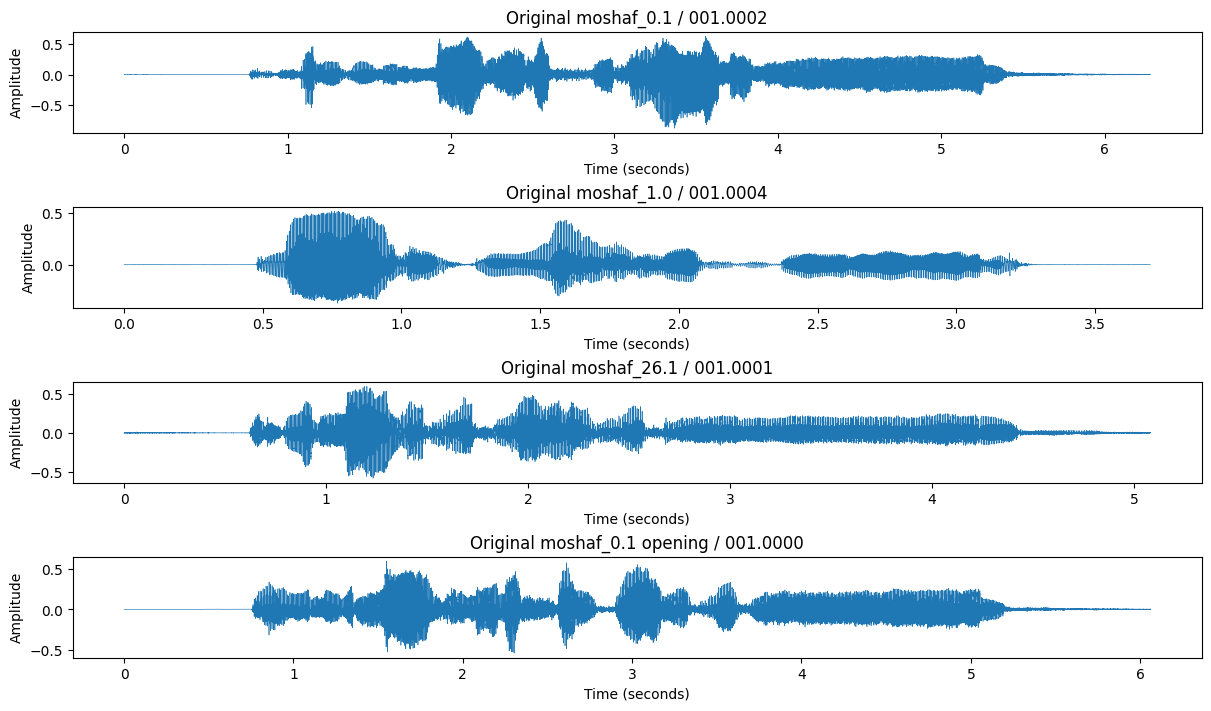

In [3]:
fig, axes = plt.subplots(len(signals), 1, figsize=(12, 7), constrained_layout=True)
for ax, (configuration, signal) in zip(axes, signals.items()):
    waveform = signal.samples[:, 0] if signal.samples.ndim == 2 else signal.samples
    time = np.arange(len(waveform)) / signal.sampling_rate
    ax.plot(time, waveform, linewidth=0.45)
    ax.set_title(f"Original {configuration} / {records[configuration]['segment_index']}")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")
plt.show()

## 4. Run the safe default pipeline

The original inference example in upstream `docs/en/muaalem/python-api.md` loads mono audio at 16 kHz; `src/quran_muaalem/inference.py` rejects rates other than 16 kHz. This dataset?s inspected samples already meet those conditions. The configured pipeline therefore checks the sample rate and float format but should not resample or rewrite these samples. Mono conversion, normalization, and denoising remain off.

In [4]:
default_outputs = {}
default_comparisons = {}
for configuration, signal in signals.items():
    output = preprocess_audio(signal, processing_config)
    default_outputs[configuration] = output
    default_comparisons[configuration] = compare_audio(signal.original, output)

default_rows = []
for configuration, output in default_outputs.items():
    comparison = default_comparisons[configuration]
    default_rows.append({
        "configuration": configuration,
        "samplewise_equal": comparison["difference"]["max_absolute"] == 0,
        "duration_delta_s": comparison["duration_delta_seconds"],
        "transformation log": [(op.name, op.applied, op.reason) for op in output.operations],
    })
display(pd.DataFrame(default_rows))

,configuration,samplewise_equal,duration_delta_s,transformation log
0,moshaf_0.1,True,0.0,"[(to_float32, False, already float32), (resamp..."
1,moshaf_1.0,True,0.0,"[(to_float32, False, already float32), (resamp..."
2,moshaf_26.1,True,0.0,"[(to_float32, False, already float32), (resamp..."
3,moshaf_0.1 opening,True,0.0,"[(to_float32, False, already float32), (resamp..."


## 5. Apply individual optional operations

These real samples are already mono, 16 kHz, and float32. Calling those steps individually is a no-op, which is the intended behavior. A different sample rate would be resampled only when its rate differs from the configured target. Denoising is explicitly called with `enabled=False`; no noise is assumed or removed.

In [5]:
example = signals["moshaf_1.0"]
individual_steps = {
    "mono conversion": convert_to_mono(example),
    "16 kHz resampling": resample_audio(example, 16000),
    "float32 conversion": to_float32(example),
    "noise reduction disabled": reduce_noise(example, enabled=False),
}
step_rows = []
for name, output in individual_steps.items():
    operation = output.operations[-1]
    step_rows.append({
        "operation": name,
        "applied": operation.applied,
        "reason": operation.reason,
        "sample count": output.samples.shape[0],
        "rate": output.sampling_rate,
        "channels": output.channels,
    })
display(pd.DataFrame(step_rows))

silence = detect_silence(signals["moshaf_0.1 opening"], threshold_dbfs=-60)
print("Measured beginning quiet interval:", silence.leading_seconds, "seconds")
print("Silence detection is measurement-only; source sample count remains:", len(signals["moshaf_0.1 opening"].samples))

,operation,applied,reason,sample count,rate,channels
0,mono conversion,False,already mono,59200,16000,1
1,16 kHz resampling,False,already at target rate,59200,16000,1
2,float32 conversion,False,already float32,59200,16000,1
3,noise reduction disabled,False,disabled,59200,16000,1


Measured beginning quiet interval: 0.4525 seconds
Silence detection is measurement-only; source sample count remains: 96960


## 6. Quiet word-ending proxy and optional normalization

The `moshaf_1.0/001.0004` annotation ends with `????????`. The dataset supplies no word/phoneme timestamps. The final 200 ms is therefore a tail proxy; its low RMS does not by itself prove which phoneme occupies every sample. Peak normalization is demonstrated as an explicitly requested, bounded operation (target ?1 dBFS, maximum gain +6 dB, and no amplification for very quiet clips).

In [6]:
quiet_config = "moshaf_1.0"
quiet_signal = signals[quiet_config]
quiet_record = records[quiet_config]
quiet_normalized = normalize_peak(
    quiet_signal,
    target_dbfs=processing_config.normalize_target_dbfs,
    max_gain_db=processing_config.normalize_max_gain_db,
    minimum_peak_dbfs=processing_config.normalize_minimum_peak_dbfs,
)
quiet_before = analyze_audio(quiet_signal, clipping_threshold=processing_config.clipping_threshold)
quiet_after = analyze_audio(quiet_normalized, clipping_threshold=processing_config.clipping_threshold)
window = int(0.2 * quiet_signal.sampling_rate)
quiet_tail_before = quiet_signal.samples[-window:, 0]
quiet_tail_after = quiet_normalized.samples[-window:, 0]
quiet_comparison = {
    "record": f"{quiet_config}/{quiet_record['segment_index']}",
    "final annotated word": quiet_record["uthmani"].split()[-1],
    "tail window seconds": window / quiet_signal.sampling_rate,
    "tail RMS before dBFS": rms_dbfs(quiet_tail_before),
    "tail RMS after dBFS": rms_dbfs(quiet_tail_after),
    "normalization gain dB": quiet_normalized.operations[-1].parameters.get("gain_db"),
    "duration preserved": quiet_before.duration_seconds == quiet_after.duration_seconds,
    "final sample nonzero before": bool(quiet_signal.samples[-1, 0] != 0),
    "final sample nonzero after": bool(quiet_normalized.samples[-1, 0] != 0),
    "tail relative shape preserved": bool(np.allclose(
        quiet_tail_after,
        quiet_tail_before * quiet_normalized.operations[-1].parameters["linear_gain"],
        rtol=1e-5, atol=1e-7,
    )),
    "clipped samples before/after": (quiet_before.clipped_sample_count, quiet_after.clipped_sample_count),
    "peak after": quiet_after.peak_amplitude,
    "original samples unchanged": bool(np.array_equal(quiet_signal.original.samples, quiet_signal.samples)),
}
display(pd.Series(quiet_comparison).to_frame("value"))

,value
record,moshaf_1.0/001.0004
final annotated word,ٱلدِّينِ
tail window seconds,0.2
tail RMS before dBFS,-63.490613
tail RMS after dBFS,-58.75578
normalization gain dB,4.734834
duration preserved,True
final sample nonzero before,True
final sample nonzero after,True
tail relative shape preserved,True


## 7. Compare the quiet ending visually and listen

The overlay covers only the final 300 ms for visibility. Uniform peak normalization raises quiet and loud samples by the same factor; it does not trim the tail or change playback speed. Audio controls are provided for listening in a notebook interface.

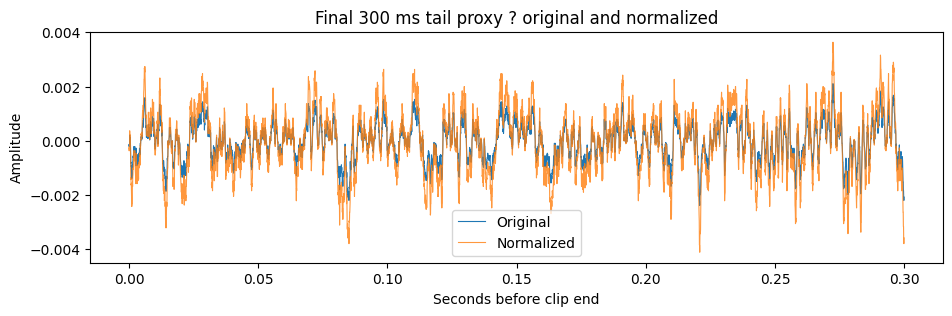

Original audio


Normalized audio


In [7]:
window = int(0.3 * quiet_signal.sampling_rate)
time = np.arange(window) / quiet_signal.sampling_rate
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(time, quiet_signal.samples[-window:, 0], label="Original", linewidth=0.8)
ax.plot(time, quiet_normalized.samples[-window:, 0], label="Normalized", linewidth=0.8, alpha=0.8)
ax.set_title("Final 300 ms tail proxy ? original and normalized")
ax.set_xlabel("Seconds before clip end")
ax.set_ylabel("Amplitude")
ax.legend()
plt.show()

print("Original audio")
display(Audio(quiet_signal.samples[:, 0], rate=quiet_signal.sampling_rate))
print("Normalized audio")
display(Audio(quiet_normalized.samples[:, 0], rate=quiet_normalized.sampling_rate))

## 8. Findings

- All 15 inspected rows across three configurations decoded as finite, mono, 16 kHz WAV audio with no samples at the configured clipping threshold.
- Peaks vary across examples; silence at the beginning ranges from near zero up to 0.453 s. That lead-in remains present.
- The safe default pipeline made no sample changes on these already mono/16 kHz/float32 examples.
- Optional normalization of the selected ending applied one uniform gain, kept duration and the final sample, and did not clip. The final 200 ms is only a tail proxy because word-level timing labels are unavailable.
- No evidence in these samples justified denoising. It remains opt-in and requires an explicit noise profile.